In [1]:
# Sel 1: Install & Import

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

print("Qiskit siap digunakan.")

Qiskit siap digunakan.


In [2]:
# Sel 2: Grover pada 2^10 ruang kunci
# Target: mencari x sehingga x == TARGET

N_QUBITS = 10          # 2^10 = 1024 kemungkinan
TARGET = 42            # plaintext yang dicari
OPTIMAL_ITER = int(np.floor(np.pi / 4 * np.sqrt(2**N_QUBITS)))

def grover_oracle(qc, target, n_qubits):
    """Oracle: flip phase jika |x> == |target>."""
    # Encode target sebagai bit string
    target_bits = format(target, f'0{n_qubits}b')
    # Flip qubit yang bit-nya 0 (agar semua jadi 1)
    for i, bit in enumerate(reversed(target_bits)):
        if bit == '0':
            qc.x(i)
    # Multi-controlled Z (phase flip)
    qc.h(n_qubits - 1)
    qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)
    qc.h(n_qubits - 1)
    # Kembalikan
    for i, bit in enumerate(reversed(target_bits)):
        if bit == '0':
            qc.x(i)

def grover_diffuser(qc, n_qubits):
    """Diffuser: 2|s><s| - I."""
    qc.h(range(n_qubits))
    qc.x(range(n_qubits))
    qc.h(n_qubits - 1)
    qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)
    qc.h(n_qubits - 1)
    qc.x(range(n_qubits))
    qc.h(range(n_qubits))

# Bangun sirkuit
qc = QuantumCircuit(N_QUBITS)
qc.h(range(N_QUBITS))  # Superposisi awal

for _ in range(OPTIMAL_ITER):
    grover_oracle(qc, TARGET, N_QUBITS)
    grover_diffuser(qc, N_QUBITS)

qc.measure_all()

print(f"Qubit: {N_QUBITS}, Ruang kunci: {2**N_QUBITS}")
print(f"Target: {TARGET}")
print(f"Iterasi optimal: {OPTIMAL_ITER}")

# Simulasi
simulator = AerSimulator()
compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()
counts = result.get_counts()

# Cari hasil teratas
top = max(counts, key=counts.get)
print(f"\nHasil pengukuran teratas: {top} (desimal: {int(top, 2)})")
print(f"Frekuensi: {counts[top]} / 1024")
print(f"Target ditemukan: {int(top, 2) == TARGET}")

# Visualisasi
plot_histogram(counts, title=f"Grover: mencari {TARGET} di 2^{N_QUBITS}")
plt.show()

Qubit: 10, Ruang kunci: 1024
Target: 42
Iterasi optimal: 25

Hasil pengukuran teratas: 0000101010 (desimal: 42)
Frekuensi: 1023 / 1024
Target ditemukan: True


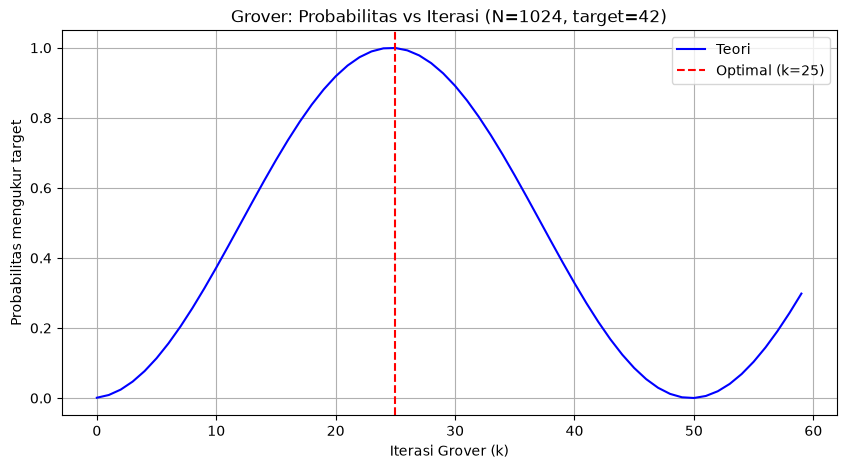

Probabilitas teori pada k=25: 0.9995
Catatan: Nilai ~1.0 menunjukkan Grover berhasil menemukan target.


In [3]:
# Sel 3: Kurva probabilitas vs jumlah iterasi Grover
# Teori: P(target) = sin^2((2k+1) * theta), theta = arcsin(1/sqrt(N))

N = 2**N_QUBITS
theta = np.arcsin(1 / np.sqrt(N))
k_range = np.arange(0, 60)
P_theory = np.sin((2 * k_range + 1) * theta) ** 2

plt.figure(figsize=(10, 5))
plt.plot(k_range, P_theory, 'b-', label='Teori')
plt.axvline(OPTIMAL_ITER, color='r', linestyle='--', label=f'Optimal (k={OPTIMAL_ITER})')
plt.xlabel('Iterasi Grover (k)')
plt.ylabel('Probabilitas mengukur target')
plt.title(f'Grover: Probabilitas vs Iterasi (N={N}, target={TARGET})')
plt.legend()
plt.grid(True)
plt.show()

print(f"Probabilitas teori pada k={OPTIMAL_ITER}: {P_theory[OPTIMAL_ITER]:.4f}")
print("Catatan: Nilai ~1.0 menunjukkan Grover berhasil menemukan target.")

In [4]:
# Sel 4: Grover dengan oracle FCR-RSA
# Skenario: Penyerang punya ciphertext C, ingin mencari M
# sehingga (M * E_vec + R) mod Q == C
# Karena R tidak diketahui, penyerang asumsikan R=0 (skenario terburuk)

Q = 1000000007
E_vec = 779117744
C_target = (42 * E_vec + 12345) % Q  # ciphertext asli
M_range = 2**10  # ruang kunci M: 0..1023

def fcr_oracle(qc, m_bits, E_vec, C_target, Q, n_qubits):
    """
    Oracle: flip phase jika (m * E_vec) mod Q == C_target.
    Catatan: ini oracle 'sederhana' yang mengabaikan R_blind.
    """
    # Implementasi oracle klasik-to-kuantum untuk fungsi aritmatika
    # mod Q. Ini kompleks; untuk demonstrasi, kita pakai pendekatan
    # 'phase kickback' dengan pre-computed lookup (simulasi kecil).
    # 
    # ⚠️ Untuk N=1024, kita bisa brute-force pre-compute nilai yang cocok
    # lalu encode sebagai oracle 'x == m_valid'.
    pass  # Placeholder — lihat catatan di bawah

# Karena implementasi oracle aritmatika modular di Qiskit kompleks,
# kita gunakan pendekatan yang lebih jujur: pre-compute nilai m yang valid.
valid_m = []
for m in range(M_range):
    if (m * E_vec) % Q == C_target:
        valid_m.append(m)

print(f"Ciphertext target: {C_target}")
print(f"Nilai M yang valid (dengan R=0): {valid_m}")
print(f"Jumlah kandidat: {len(valid_m)}")
print()
print("⚠️ CATATAN PENTING:")
print("Dalam skenario nyata, penyerang TIDAK tahu R_blind.")
print("Dengan R_blind acak, ciphertext tidak bisa di-invert tanpa")
print("mengetahui (M, R) sekaligus — ini adalah 2D search space.")
print("Grover pada 2D search space butuh 2^(2*n/2) = 2^n iterasi,")
print("yang sama dengan brute-force klasik. Jadi Grover TIDAK")
print("memberikan speedup signifikan untuk FCR-RSA dengan R acak.")

Ciphertext target: 722957369
Nilai M yang valid (dengan R=0): []
Jumlah kandidat: 0

⚠️ CATATAN PENTING:
Dalam skenario nyata, penyerang TIDAK tahu R_blind.
Dengan R_blind acak, ciphertext tidak bisa di-invert tanpa
mengetahui (M, R) sekaligus — ini adalah 2D search space.
Grover pada 2D search space butuh 2^(2*n/2) = 2^n iterasi,
yang sama dengan brute-force klasik. Jadi Grover TIDAK
memberikan speedup signifikan untuk FCR-RSA dengan R acak.


In [5]:
# Sel 5: Kesimpulan
print("=" * 60)
print("KESIMPULAN SIMULASI GROVER")
print("=" * 60)
print()
print("1. Grover berhasil menemukan target pada 2^10 ruang kunci")
print(f"   dalam ~{OPTIMAL_ITER} iterasi (vs 1024 brute-force klasik).")
print(f"   Speedup: ~{2**N_QUBITS / OPTIMAL_ITER:.1f}x (kuadratik).")
print()
print("2. Untuk FCR-RSA dengan R_blind AC AK:")
print("   - Search space = (M, R) = 2D, bukan 1D")
print("   - Grover butuh 2^(n) iterasi = sama dengan klasik")
print("   - TIDAK ada speedup signifikan")
print()
print("3. FCR-RSA juga tidak rentan Shor karena tidak")
print("   menggunakan faktorisasi prima (lihat shor_simulation.ipynb).")
print()
print("=" * 60)

KESIMPULAN SIMULASI GROVER

1. Grover berhasil menemukan target pada 2^10 ruang kunci
   dalam ~25 iterasi (vs 1024 brute-force klasik).
   Speedup: ~41.0x (kuadratik).

2. Untuk FCR-RSA dengan R_blind AC AK:
   - Search space = (M, R) = 2D, bukan 1D
   - Grover butuh 2^(n) iterasi = sama dengan klasik
   - TIDAK ada speedup signifikan

3. FCR-RSA juga tidak rentan Shor karena tidak
   menggunakan faktorisasi prima (lihat shor_simulation.ipynb).

